# Surface-driven model comparisons

Compare GBM, **calibrated Heston** and **Dupire Local Vol** with the same dated spot/carry inputs and contract monitoring. Quotes and curves are the saved 2026-10-08 LSEG SPXW capture; barrier and note terms below are **synthetic teaching contracts**. No live session, verified vendor volatility surface or observed issued note is used.

The original quote-derived SSVI fit and the smooth Dupire export are distinct. Quote-fit errors measure market fit; native MC/PDE residuals against independent smooth-surface Black prices measure numerical implementation. Sampling intervals exclude discretisation, calibration and extension uncertainty. [Module conventions and independent sources](../docs/local_volatility.md).

In [1]:
from pathlib import Path
from datetime import date, timedelta
from time import perf_counter
import json
import math
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import fuzzy_enigma as fe

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from tools.market_validation import context_from_snapshot
from tools.market_validation.snapshot import read_snapshot, versions
from tools.market_validation.analytics import validate_snapshot, black_price
from tools.market_validation.calibration import calibrate, representatives, heston_price
from tools.market_validation.surface import fit_ssvi, VolSurface
from tools.market_validation.local_vol import export_local_vol, finite_difference_price

STARTED = perf_counter()
PATHS, SEED, STARTS = 16_000, 42, 8
GRID_DAYS = (1.0, 0.5)
# Declared before computing any numerical benchmarks; not quote-fit tolerances.
MC_BUDGET_SPOT_FRACTION = 0.002
PDE_BUDGET_SPOT_FRACTION = 0.0005
PDE_MESHES = ((401, 400), (801, 800))
FIXTURE = ROOT / "tests/fixtures/market/lseg_spxw_20261008_surface.json"
OUTPUT = ROOT / "artifacts/local_vol_model_comparison"
OUTPUT.mkdir(parents=True, exist_ok=True)
snapshot = read_snapshot(FIXTURE)
context, audit = context_from_snapshot(snapshot, currency="USD")
validated = validate_snapshot(snapshot)
fit_started = perf_counter()
ssvi_fit = fit_ssvi(validated, starts=STARTS, seed=SEED, maxiter=2000, diagnostics=False)
heston_fit = calibrate(validated, starts=STARTS, seed=SEED, max_nfev=500)
assert ssvi_fit["status"] == heston_fit["status"] == "converged"
(OUTPUT / "ssvi_fit.json").write_text(json.dumps(ssvi_fit, indent=2, sort_keys=True), encoding="utf-8")
(OUTPUT / "heston_fit.json").write_text(json.dumps(heston_fit, indent=2, sort_keys=True), encoding="utf-8")
original = VolSurface.from_dict(ssvi_fit["surface"])
smooth = export_local_vol(original, context=context, min_denominator=1e-10)
smooth.save(OUTPUT / "surface.json")
local_vol = fe.LocalVolModel.load(str(OUTPUT / "surface.json"))
FIT_SECONDS = perf_counter() - fit_started
AS_OF, SPOT = context.cutoff.as_of, context.spot
MATURITY = original.nodes[-1]["expiry"]
T = original.nodes[-1]["t"]
GBM_VOL = math.sqrt(original.nodes[-1]["theta"] / T)
HESTON_PARAMS = heston_fit["params"]
models = {"GBM": fe.GbmDynamics(GBM_VOL),
          "Heston": fe.HestonDynamics(**HESTON_PARAMS),
          "Local Vol": local_vol}
engine = fe.McEngine(paths=PATHS, seed=SEED, antithetic=True, parallel=True)
config = dict(snapshot=FIXTURE.name, as_of=AS_OF, currency="USD", asset=context.asset,
              dataset_sha256=snapshot["dataset_sha256"], context_sha256=context.identity,
              smooth_sha256=local_vol.identity, paths=PATHS, seed=SEED, starts=STARTS,
              antithetic=True, parallel=True, max_step_days=GRID_DAYS,
              ssvi_settings=ssvi_fit["settings"], heston_settings=heston_fit["settings"],
              gbm_volatility=GBM_VOL, heston=HESTON_PARAMS,
              day_count="ACT/365F", monitoring="explicit contract dates",
              theta_floor_policy="1% of first ATM total-variance node; global shifted phi",
              wings="full analytic SSVI; no clamping", versions=versions(),
              mc_budget=f"4 SE + {MC_BUDGET_SPOT_FRACTION} * spot",
              pde_budget=f"{PDE_BUDGET_SPOT_FRACTION} * spot",
              pde_meshes=PDE_MESHES, pde_x_bounds=[-2, 2], fit_seconds=FIT_SECONDS)
print(json.dumps(config, indent=2, sort_keys=True))
print("Curve provenance:", json.dumps(audit, indent=2, sort_keys=True))
smooth_diagnostics = smooth.diagnostics()
print("Smooth export diagnostics:", json.dumps({k: v for k, v in smooth_diagnostics.items() if k != "export_report"}, indent=2, sort_keys=True))
(OUTPUT / "export_report.json").write_text(json.dumps(smooth.export_report, indent=2, sort_keys=True), encoding="utf-8")

{
  "antithetic": true,
  "as_of": "2026-10-08",
  "asset": ".SPX",
  "context_sha256": "f8706d73545acf8fa842478b2691e8fd5c504417bd68e6426141c885ca132ccc",
  "currency": "USD",
  "dataset_sha256": "6a6a20fe0a700a3a560bf520e88f6bc84fbf186c6fd22bc7989f85307c68ba1f",
  "day_count": "ACT/365F",
  "fit_seconds": 7.407057458010968,
  "gbm_volatility": 0.1436879546614041,
  "heston": {
    "kappa": 19.999999999999158,
    "rho": -0.6196433485467475,
    "theta": 0.03291341202024776,
    "v0": 0.0055495111950279044,
    "xi": 3.0949998703195556
  },
  "heston_settings": {
    "bounds": {
      "kappa": [
        0.001,
        20.0
      ],
      "rho": [
        -0.999,
        0.999
      ],
      "theta": [
        1e-06,
        4.0
      ],
      "v0": [
        1e-06,
        4.0
      ],
      "xi": [
        0.0001,
        5.0
      ]
    },
    "loss": "soft_l1",
    "max_nfev": 500,
    "method": "trf",
    "seed": 42,
    "split": "every fifth unique strike per expiry; call/put sha

## Smooth smiles, origin and analytic wings

The exporter interpolates ATM total variance with monotone C1 PCHIP through `(0, 0)` and globally replaces the original skew denominator by `sqrt((theta + theta_floor)*(1+theta))`. The short-time policy therefore changes the original fit and is visible in the smiles. The heatmap shows local volatility over a plotting window; the simulation uses full analytic wings rather than this finite plotting window.

Original-to-smooth export summary: {
  "artifact_sha256": "31eeefde2fea90c020881b1f0cbca0ac5bdc3fd734d200fbd528c0f27b5450e1",
  "max_abs_call_price_change": 4.2313746654587305,
  "max_abs_iv_change_bp": 23.355038457158194,
  "meaning": "smooth-model changes relative to the original fit; these differences are separate from original market calibration residuals",
  "quote_surface_unchanged": true,
  "report_type": "local_vol_smooth_export",
  "schema_version": 1,
  "smoothness": "C1 theta; continuous w_t at time knots; one-sided final support boundary",
  "source_fit_status": "converged",
  "source_surface_sha256": "e881c4666dc65b9b48ad0590bb766cf63385694b4a6ff70884f8872275d32c92",
  "status": "accepted",
  "theta_floor": 1.371577260822855e-06,
  "theta_floor_basis": "0.01 * first fitted ATM variance"
}
Full original-to-smooth residuals are retained in export_report.json.


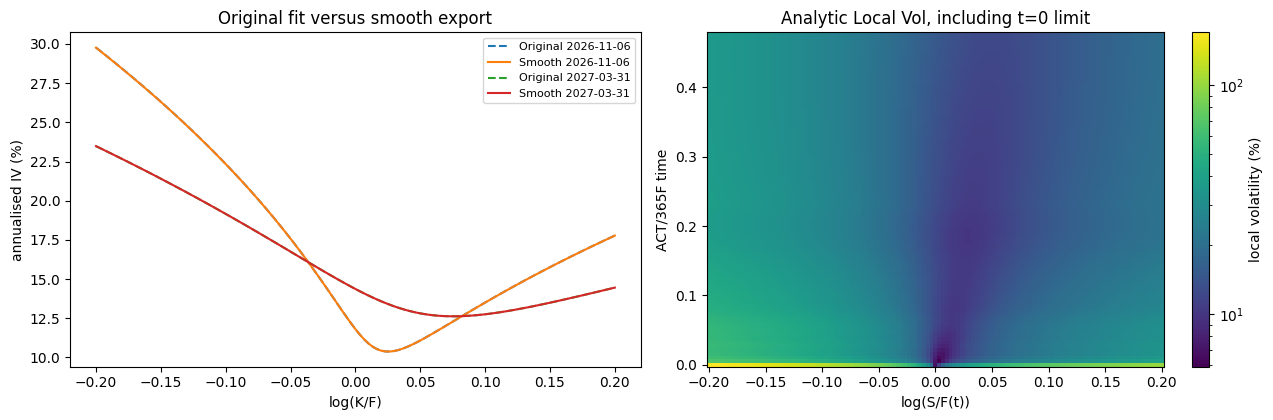

In [2]:
ks = np.linspace(-0.20, 0.20, 121)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for node in (original.nodes[2], original.nodes[-1]):
    t = node["t"]
    old_iv = [math.sqrt(original.total_variance(k, t, allow_wing=True) / t) for k in ks]
    new_iv = [math.sqrt(smooth.total_variance(k, t) / t) for k in ks]
    axes[0].plot(ks, np.array(old_iv)*100, "--", label=f"Original {node['expiry']}")
    axes[0].plot(ks, np.array(new_iv)*100, label=f"Smooth {node['expiry']}")
axes[0].set(xlabel="log(K/F)", ylabel="annualised IV (%)", title="Original fit versus smooth export")
axes[0].legend(fontsize=8)
times = np.linspace(0.0, T, 90)
local_grid = np.array([[math.sqrt(smooth.local_variance(float(k), float(t))) for k in ks] for t in times])
image = axes[1].pcolormesh(ks, times, local_grid*100, shading="auto", cmap="viridis",
                               norm=LogNorm(vmin=float(local_grid.min()*100), vmax=float(local_grid.max()*100)))
axes[1].set(xlabel="log(S/F(t))", ylabel="ACT/365F time", title="Analytic Local Vol, including t=0 limit")
fig.colorbar(image, ax=axes[1], label="local volatility (%)")
fig.tight_layout()
plt.show()
print("Original-to-smooth export summary:", json.dumps({k: v for k, v in smooth.export_report.items() if k != "differences"}, indent=2, sort_keys=True))
print("Full original-to-smooth residuals are retained in export_report.json.")

## Original quote residuals, with a fixed training/holdout split

GBM volatility is the terminal ATM level of the training-only SSVI fit. Heston is fitted using independent analytic prices, eight starts and the existing fixed weights/split. Original and smooth SSVI are compared to the same OTM representatives on qualifying expiries. These numbers do not measure Local Vol simulation accuracy. The smooth exporter does not refit to holdout quotes.

Original Close residuals (index points):
                        count     rmse      mae
model         split                           
GBM           holdout     12  15.3112  12.0232
              train       58  15.2508  11.2026
Heston        holdout     12  10.4292   5.2873
              train       58   4.2375   2.2665
Original SSVI holdout     12   6.1453   3.6428
              train       58   2.6911   1.7166
Smooth SSVI   holdout     12   6.1448   3.6435
              train       58   2.6908   1.7153


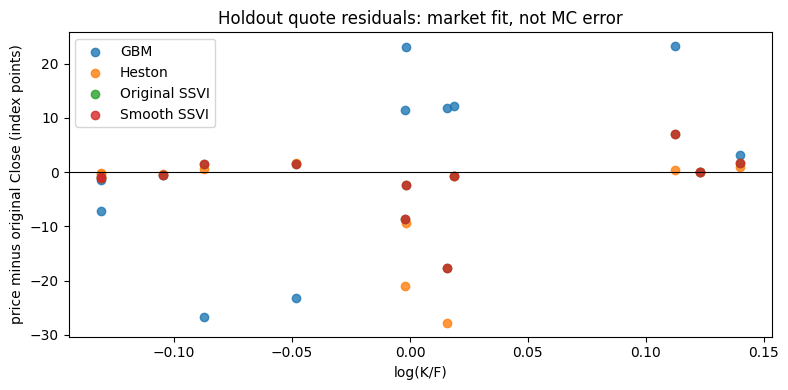

In [3]:
market_rows = [r for r in representatives(validated["accepted"])
               if r["expiry"] in ssvi_fit["qualifying_expiries"]]
quote_records = []
for row in market_rows:
    k, t = math.log(row["strike"] / row["forward"]), row["t"]
    prices = {"GBM": black_price(row, GBM_VOL),
              "Heston": heston_price(row, HESTON_PARAMS),
              "Original SSVI": black_price(row, math.sqrt(original.total_variance(k, t, allow_wing=True)/t)),
              "Smooth SSVI": black_price(row, math.sqrt(smooth.total_variance(k, t)/t))}
    for model, price in prices.items():
        quote_records.append(dict(model=model, expiry=row["expiry"], strike=row["strike"],
                                  k=k, split=row["split"], close=row["close"], price=price,
                                  error=price-row["close"]))
quote_df = pd.DataFrame(quote_records)
quote_summary = quote_df.groupby(["model", "split"]).agg(
    count=("error", "size"), rmse=("error", lambda e: float(np.sqrt(np.mean(e*e)))),
    mae=("error", lambda e: float(np.mean(np.abs(e)))))
print("Original Close residuals (index points):\n", quote_summary.round(4).to_string())
fig, ax = plt.subplots(figsize=(8, 4))
for model, group in quote_df[quote_df.split == "holdout"].groupby("model", sort=False):
    ax.scatter(group.k, group.error, label=model, alpha=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="log(K/F)", ylabel="price minus original Close (index points)",
       title="Holdout quote residuals: market fit, not MC error")
ax.legend()
fig.tight_layout()
plt.show()
quote_df.to_csv(OUTPUT / "original_quote_residuals.csv", index=False)

## Independent PDE mesh refinement

The finite-difference reference uses a separate normalised call-price grid. Independent QuantLib Black prices use smooth total variance and the exact same dated D/F endpoints. The coarse and fine meshes, truncation window and budgets above are declared before pricing. A passing budget is a numerical check, not evidence that the wing/short-time extension is the market model.

In [4]:
BENCHMARK_EXPIRIES = (original.nodes[2]["expiry"], MATURITY)
BENCHMARK_K = (-0.06, 0.0, 0.06)
benchmark_rows, pde_records = [], []
for expiry in BENCHMARK_EXPIRIES:
    t = (date.fromisoformat(expiry)-date.fromisoformat(AS_OF)).days / 365
    forward = context.forward_curve.value(expiry)
    for k in BENCHMARK_K:
        strike = forward * math.exp(k)
        row = dict(kind="call", strike=strike, forward=forward, t=t,
                   discount_factor=context.discount_curve.value(expiry))
        reference = black_price(row, math.sqrt(smooth.total_variance(k, t)/t))
        benchmark_rows.append(dict(expiry=expiry, k=k, strike=strike, reference=reference))
        for nx, nt in PDE_MESHES:
            result = finite_difference_price(smooth, "call", strike, expiry,
                                             space_points=nx, time_steps=nt, x_bounds=(-2, 2))
            pde_records.append(dict(expiry=expiry, k=k, strike=strike, reference=reference,
                                    space_points=nx, time_steps=nt, actual_time_steps=result["actual_time_steps"],
                                    dx=result["dx"], price=result["price"],
                                    error=result["price"]-reference, elapsed_seconds=result["elapsed_seconds"]))
pde_df = pd.DataFrame(pde_records)
pde_df["within_declared_budget"] = abs(pde_df.error) <= PDE_BUDGET_SPOT_FRACTION * SPOT
print(pde_df.round(5).to_string(index=False))
print("PDE coarse-to-fine changes (index points):")
for (expiry, k), group in pde_df.groupby(["expiry", "k"]):
    print(expiry, k, float(group.iloc[-1].price-group.iloc[0].price))
assert pde_df.within_declared_budget.all()
pde_df.to_csv(OUTPUT / "pde_refinement.csv", index=False)

    expiry     k     strike  reference  space_points  time_steps  actual_time_steps    dx     price    error  elapsed_seconds  within_declared_budget
2026-11-06 -0.06 7329.00951  476.61338           401         400                404 0.010 475.75054 -0.86284          0.78271                    True
2026-11-06 -0.06 7329.00951  476.61338           801         800                804 0.005 476.39843 -0.21495          9.10333                    True
2026-11-06  0.00 7782.21014  102.99999           401         400                404 0.010 101.27983 -1.72015          3.11292                    True
2026-11-06  0.00 7782.21014  102.99999           801         800                804 0.005 102.57436 -0.42563          7.96220                    True
2026-11-06  0.06 8263.43514    3.32506           401         400                404 0.010   3.59155  0.26649          1.24874                    True
2026-11-06  0.06 8263.43514    3.32506           801         800                804 0.005   3.39991 

## Native MC vanilla residuals and simulation-grid refinement

Only the Local Vol row is expected to reproduce the smooth surface's vanilla reference. GBM/Heston differences include their different marginal fits. Each MC SE is computed from complete discounted path cashflows. The same seed at a different step count does not provide a paired-difference SE, so both individual SEs are shown. The illustrative acceptance budget includes a separately stated discretisation allowance.

    model     expiry     k  max_step_days     price  std_error  samples  paths  steps  reference    error  elapsed_seconds  within_declared_budget
Local Vol 2026-11-06 -0.06            1.0 477.03493    0.51822     8000  16000     29  476.61338  0.42155          0.01386                    True
Local Vol 2026-11-06 -0.06            0.5 475.91201    0.50602     8000  16000     58  476.61338 -0.70137          0.06556                    True
Local Vol 2026-11-06  0.00            1.0 104.68446    0.75730     8000  16000     29  102.99999  1.68448          0.01028                    True
Local Vol 2026-11-06  0.00            0.5 103.69951    0.73492     8000  16000     58  102.99999  0.69953          0.03192                    True
Local Vol 2026-11-06  0.06            1.0   3.66668    0.27623     8000  16000     29    3.32506  0.34162          0.01067                    True
Local Vol 2026-11-06  0.06            0.5   3.20488    0.25514     8000  16000     58    3.32506 -0.12018          0.0

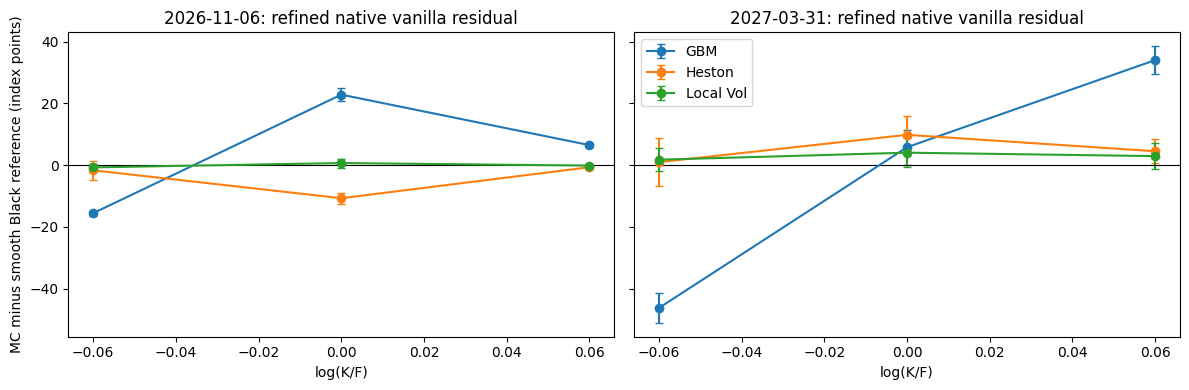

In [5]:
mc_records, exposure_records = [], []
for benchmark in benchmark_rows:
    for step_days in GRID_DAYS:
        grid = fe.TimeGrid(AS_OF, [benchmark["expiry"]], max_step_days=step_days)
        for model, dynamics in models.items():
            started = perf_counter()
            result = engine.price_european_context(context, dynamics, "call", benchmark["strike"],
                                                   benchmark["expiry"], grid=grid)
            mc_records.append(dict(model=model, expiry=benchmark["expiry"], k=benchmark["k"],
                                   max_step_days=step_days, price=result.price,
                                   std_error=result.std_error, samples=result.samples, paths=result.paths, steps=grid.steps,
                                   reference=benchmark["reference"],
                                   error=result.price-benchmark["reference"],
                                   elapsed_seconds=perf_counter()-started))
            if result.path_diagnostics is not None:
                exposure_records.append(dict(product="European", expiry=benchmark["expiry"],
                                             k=benchmark["k"], max_step_days=step_days,
                                             **result.path_diagnostics))
mc_df = pd.DataFrame(mc_records)
local_mc = mc_df[mc_df.model == "Local Vol"].copy()
local_mc["within_declared_budget"] = abs(local_mc.error) <= 4*local_mc.std_error + MC_BUDGET_SPOT_FRACTION*SPOT
print(local_mc.round(5).to_string(index=False))
assert local_mc.within_declared_budget.all()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, expiry in zip(axes, BENCHMARK_EXPIRIES):
    for model, group in mc_df[(mc_df.expiry == expiry) & (mc_df.max_step_days == GRID_DAYS[-1])].groupby("model", sort=False):
        ax.errorbar(group.k, group.error, yerr=1.96*group.std_error, marker="o", capsize=3, label=model)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xlabel="log(K/F)", title=f"{expiry}: refined native vanilla residual")
axes[0].set_ylabel("MC minus smooth Black reference (index points)")
axes[1].legend()
fig.tight_layout()
plt.show()
mc_df.to_csv(OUTPUT / "native_vanilla.csv", index=False)

## Identical synthetic path-dependent contracts

The barrier is an up-and-out call observed weekly, including inception and maturity. The Snowball and memory Phoenix use the same weekly KI dates and independently supplied coupon/autocall dates. All dates are actual caller-supplied dates without automatic holiday adjustment. Numerical half-day refinement introduces no new barrier or KI fixings. Notes have 100 USD principal, while vanilla/barrier premiums are index points; prices with different units are never aggregated.

 product     model  max_step_days     price  std_error  samples  paths  steps                  unit  elapsed_seconds
 Barrier       GBM            1.0 110.69641    1.42508     8000  16000    174          index points          0.01161
Snowball       GBM            1.0 102.40760    0.01837     8000  16000    174 USD per 100 principal          0.02563
 Phoenix       GBM            1.0 103.40213    0.00983     8000  16000    174 USD per 100 principal          0.06763
 Barrier    Heston            1.0 214.50273    2.11698     8000  16000    174          index points          0.01818
Snowball    Heston            1.0 100.85912    0.05540     8000  16000    174 USD per 100 principal          0.06541
 Phoenix    Heston            1.0 102.21023    0.05129     8000  16000    174 USD per 100 principal          0.04510
 Barrier Local Vol            1.0 189.88916    1.70214     8000  16000    174          index points          0.06047
Snowball Local Vol            1.0 100.27334    0.06534     8000 

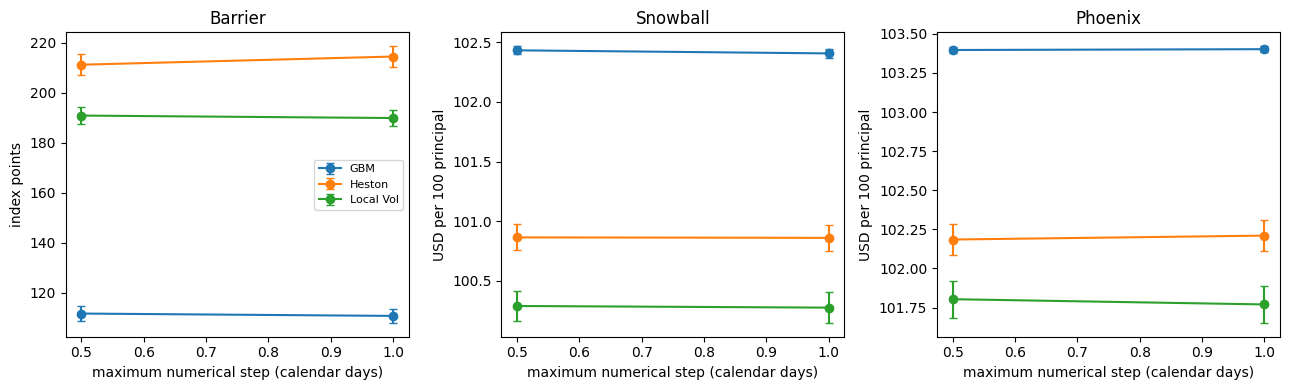

In [6]:
issue = date.fromisoformat(AS_OF)
end = date.fromisoformat(MATURITY)
monitoring_dates = sorted({issue.isoformat(), end.isoformat(),
                          *((issue+timedelta(days=d)).isoformat() for d in range(7, (end-issue).days, 7))})
OBSERVATIONS = ["2026-11-06", "2026-12-04", "2026-12-31", MATURITY]
calendar_source = "synthetic teaching schedule; actual dates, no holiday adjustment"
coupons = fe.EventSchedule(OBSERVATIONS, OBSERVATIONS, calendar_source)
autocall_dates = OBSERVATIONS[1:]
autocalls = fe.EventSchedule(autocall_dates, autocall_dates, calendar_source)
maturity_schedule = fe.EventSchedule([MATURITY], [MATURITY], calendar_source)
snowball = fe.DatedSnowballNote(100, SPOT, 0.12, 0.78*SPOT, 1.025*SPOT,
                                AS_OF, "USD", context.asset, monitoring_dates,
                                autocalls, maturity_schedule)
phoenix = fe.DatedPhoenixNote(100, SPOT, 1.5, 0.85*SPOT, 0.75*SPOT, 1.04*SPOT,
                              AS_OF, "USD", context.asset, monitoring_dates,
                              coupons, autocalls, maturity_schedule, memory=True)
snowball_state = fe.replay_note_history(snowball, [], context.cutoff)
phoenix_state = fe.replay_note_history(phoenix, [], context.cutoff)
ALL_FIXINGS = sorted(set(monitoring_dates) | set(OBSERVATIONS))
product_records = []
for step_days in GRID_DAYS:
    grid = fe.TimeGrid(AS_OF, ALL_FIXINGS, max_step_days=step_days)
    for model, dynamics in models.items():
        operations = {
            "Barrier": lambda: engine.price_barrier_context(context, dynamics, "call", SPOT,
                      MATURITY, "up_and_out", 1.12*SPOT, monitoring_dates, rebate=0, grid=grid),
            "Snowball": lambda: engine.price_snowball_dated(snowball, context, dynamics, snowball_state, grid=grid),
            "Phoenix": lambda: engine.price_phoenix_dated(phoenix, context, dynamics, phoenix_state, grid=grid),
        }
        for product, operation in operations.items():
            started = perf_counter()
            result = operation()
            product_records.append(dict(product=product, model=model, max_step_days=step_days,
                                        price=result.price, std_error=result.std_error,
                                        samples=result.samples, paths=result.paths, steps=grid.steps,
                                        unit="index points" if product == "Barrier" else "USD per 100 principal",
                                        elapsed_seconds=perf_counter()-started))
            if result.path_diagnostics is not None:
                exposure_records.append(dict(product=product, expiry=MATURITY, k=None,
                                             max_step_days=step_days, **result.path_diagnostics))
product_df = pd.DataFrame(product_records)
print(product_df.round(5).to_string(index=False))
print("Grid refinement: fine minus coarse PV; individual SEs remain in the table")
print(product_df.pivot(index=["product", "model"], columns="max_step_days", values="price")
      .assign(fine_minus_coarse=lambda d: d[GRID_DAYS[-1]]-d[GRID_DAYS[0]]).round(5).to_string())
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, product in zip(axes, ("Barrier", "Snowball", "Phoenix")):
    for model, group in product_df[product_df["product"] == product].groupby("model", sort=False):
        ax.errorbar(group.max_step_days, group.price, yerr=1.96*group.std_error, marker="o", capsize=3, label=model)
    ax.set(xlabel="maximum numerical step (calendar days)", title=product,
           ylabel="index points" if product == "Barrier" else "USD per 100 principal")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
product_df.to_csv(OUTPUT / "synthetic_contracts.csv", index=False)

## Extension exposure and provenance

Exposure counts describe left-end grid states where volatility is queried; the terminal fixing is not an extra volatility query. They do not measure between-grid continuous excursions. Every non-flat Local Vol path starts in the declared short-time extension. The last fitted expiry has limited observed downside coverage, so analytic-wing exposure can be substantial. Full analytic coverage allows simulation; it does not certify unobserved market wings. A structured-note price difference cannot be assigned solely to dynamics when the models have different vanilla fit errors.

In [7]:
exposure_df = pd.DataFrame(exposure_records)
print("Local Vol evaluation exposure:\n", exposure_df.to_string(index=False))
exposure_df.to_csv(OUTPUT / "extension_exposure.csv", index=False)
config["elapsed_seconds"] = perf_counter()-STARTED
summary = dict(config=config, original_quote_metrics=quote_summary.reset_index().to_dict(orient="records"),
               smooth_diagnostics=smooth.diagnostics(),
               pde_max_abs_error=float(abs(pde_df.error).max()),
               local_vol_mc_max_abs_error=float(abs(local_mc.error).max()),
               all_pde_within_budget=bool(pde_df.within_declared_budget.all()),
               all_local_vol_mc_within_budget=bool(local_mc.within_declared_budget.all()),
               synthetic_terms=True, no_surface_roll=True,
               note="MC SE excludes discretisation, fit and extension uncertainty")
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2, sort_keys=True), encoding="utf-8")
print("Total elapsed seconds:", round(config["elapsed_seconds"], 2))
print("Saved reproducible artifacts:", OUTPUT.relative_to(ROOT))
print("Model identity:", local_vol.identity)

Local Vol evaluation exposure:
  product     expiry     k  max_step_days  evaluations  outside_observed_evaluations  wing_evaluations  short_time_evaluations  paths_with_extensions  minimum_k  maximum_k                                                            extension_policy
European 2026-11-06 -0.06            1.0       464000                        112535               535                  112000                  16000  -0.539580   0.201197 global_shifted_phi; analytic_ssvi_all_real_k; bounded_no_long_extrapolation
European 2026-11-06 -0.06            0.5       928000                        225169              1169                  224000                  16000  -0.564867   0.204999 global_shifted_phi; analytic_ssvi_all_real_k; bounded_no_long_extrapolation
European 2026-11-06  0.00            1.0       464000                        112535               535                  112000                  16000  -0.539580   0.201197 global_shifted_phi; analytic_ssvi_all_real_k; bounded_no